# Scoring de crédit explicable : analyse

Jeu **Default of Credit Card Clients** (Taiwan, 2005), UCI, identifiant 350,
licence CC BY 4.0. Cible `DEFAULT` : défaut de paiement le mois suivant (1 = défaut).

Ce notebook utilise le même code que l'application (`src/credit_scoring`).

## 1. Données : vérifications avant utilisation

Objectif : vérifier sur les vraies données ce qui est annoncé (dimensions, absence de valeurs
manquantes, taux de défaut) et examiner les modalités non documentées avant de décider
d'un recodage. Les décisions sont détaillées dans `docs/CHOIX.md` (C04, R1 à R5).

In [1]:
from math import comb, sqrt

import pandas as pd

from credit_scoring.config import (
    BILL_FEATURES, PAY_AMT_FEATURES, PAY_STATUS_FEATURES, TARGET,
)
from credit_scoring.data import load_credit_data, recode_undocumented

pd.set_option("display.max_columns", 30)
raw = load_credit_data()  # téléchargement au premier appel, puis cache local
raw.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
ID,,,,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 1.1 Dimensions, types, valeurs manquantes

In [2]:
print("Dimensions :", raw.shape)
print("Types :", raw.dtypes.astype(str).value_counts().to_dict())
print("Valeurs manquantes :", int(raw.isna().sum().sum()))

Dimensions : (30000, 24)
Types : {'int64': 24}
Valeurs manquantes : 0


Toutes les colonnes sont des entiers, y compris `SEX`, `EDUCATION` et `MARRIAGE`, qui sont
pourtant des catégories sans ordre : elles seront déclarées explicitement comme catégorielles (P01).

### 1.2 Taux de défaut

In [3]:
counts = raw[TARGET].value_counts().rename("clients").to_frame()
counts["part (%)"] = (counts["clients"] / len(raw) * 100).round(2)
counts

,clients,part (%)
DEFAULT,,
0,23364,77.88
1,6636,22.12


Environ 22 % de défauts : un modèle qui prédirait toujours « pas de défaut » aurait 78 % de
bonnes réponses tout en étant inutile. Les modèles seront donc comparés sur l'AUC, le rappel et la
PR-AUC plutôt que sur le taux de bonnes réponses.

### 1.3 Variables catégorielles et modalités non documentées

Codes officiels (UCI) : SEX 1 = homme, 2 = femme ; EDUCATION 1 = 3e cycle, 2 = université,
3 = lycée, 4 = autres ; MARRIAGE 1 = marié, 2 = célibataire, 3 = autres.

In [4]:
def taux_par_modalite(df, col):
    """Effectif et taux de défaut (%) par modalité d'une variable."""
    t = df.groupby(col)[TARGET].agg(clients="size", defauts="sum", taux_defaut="mean")
    t["taux_defaut"] = (t["taux_defaut"] * 100).round(1)
    return t.T


taux_par_modalite(raw, "SEX")

SEX,1,2
clients,11888.0,18112.0
defauts,2873.0,3763.0
taux_defaut,24.2,20.8


In [5]:
taux_par_modalite(raw, "EDUCATION")

EDUCATION,0,1,2,3,4,5,6
clients,14.0,10585.0,14030.0,4917.0,123.0,280.0,51.0
defauts,0.0,2036.0,3330.0,1237.0,7.0,18.0,8.0
taux_defaut,0.0,19.2,23.7,25.2,5.7,6.4,15.7


Les codes 0, 5 et 6 ne sont pas documentés par l'UCI (la description Kaggle du même jeu indique
5 = unknown et 6 = unknown ; le code 0 n'est documenté nulle part). Ils concernent 345 clients (1,2 %),
avec un taux de défaut bas, proche de celui du code 4 « autres ». **R1 :** regroupement dans 4,
libellé « Autres ou inconnu ».

In [6]:
taux_par_modalite(raw, "MARRIAGE")

MARRIAGE,0,1,2,3
clients,54.0,13659.0,15964.0,323.0
defauts,5.0,3206.0,3341.0,84.0
taux_defaut,9.3,23.5,20.9,26.0


Le code 0 n'est pas documenté. Son taux de défaut (9,3 %) semble très différent de celui de
« autres » (26,0 %) : on le vérifie par un test exact de Fisher (adapté aux petits effectifs).

In [7]:
def fisher_bilateral(d0, n0, d1, n1):
    """Test exact de Fisher bilatéral sur un tableau 2x2 (défauts / clients de deux groupes)."""
    k_tot, n_tot = d0 + d1, n0 + n1

    def proba(k):
        return comb(k_tot, k) * comb(n_tot - k_tot, n0 - k) / comb(n_tot, n0)

    p_obs = proba(d0)
    support = range(max(0, n0 - (n_tot - k_tot)), min(k_tot, n0) + 1)
    return sum(proba(k) for k in support if proba(k) <= p_obs * (1 + 1e-9))


def wilson(d, n, z=1.959964):
    """Intervalle de confiance à 95 % d'une proportion (méthode de Wilson)."""
    p = d / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    demi = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return round(100 * (centre - demi), 1), round(100 * (centre + demi), 1)


groupes = raw.groupby("MARRIAGE")[TARGET].agg(defauts="sum", clients="size")
d0, n0 = groupes.loc[0]
d3, n3 = groupes.loc[3]
print(f"Code 0 : {d0}/{n0} = {d0 / n0:.1%}, IC 95 % {wilson(d0, n0)}")
print(f"Code 3 : {d3}/{n3} = {d3 / n3:.1%}, IC 95 % {wilson(d3, n3)}")
print(f"Test exact de Fisher bilatéral : p = {fisher_bilateral(d0, n0, d3, n3):.4f}")

Code 0 : 5/54 = 9.3%, IC 95 % (4.0, 19.9)
Code 3 : 84/323 = 26.0%, IC 95 % (21.5, 31.1)
Test exact de Fisher bilatéral : p = 0.0055


L'écart est **statistiquement significatif** (p < 0,05) et les intervalles de confiance ne se
chevauchent pas. **R2 :** le code 0 est tout de même regroupé avec 3, parce qu'il n'a pas de sens
documenté et que 54 clients sur 30 000 ne peuvent pas peser sur le modèle. Conséquence : le taux de
« autres » passe de 26,0 % à 23,6 %.

### 1.4 Statuts de remboursement PAY_*

Documentation UCI : -1 = payé à temps, 1…9 = mois de retard. Les codes -2 et 0 ne sont pas documentés.
PAY_0 = septembre, PAY_2 = août, …, PAY_6 = avril.

In [8]:
modalites_pay = pd.DataFrame({c: raw[c].value_counts() for c in PAY_STATUS_FEATURES})
modalites_pay.fillna(0).astype(int).sort_index().T

,-2,-1,0,1,2,3,4,5,6,7,8
PAY_0,2759,5686,14737,3688,2667,322,76,26,11,9,19
PAY_2,3782,6050,15730,28,3927,326,99,25,12,20,1
PAY_3,4085,5938,15764,4,3819,240,76,21,23,27,3
PAY_4,4348,5687,16455,2,3159,180,69,35,5,58,2
PAY_5,4546,5539,16947,0,2626,178,84,17,4,58,1
PAY_6,4895,5740,16286,0,2766,184,49,13,19,46,2


In [9]:
taux_par_modalite(raw, "PAY_0")

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
clients,2759.0,5686.0,14737.0,3688.0,2667.0,322.0,76.0,26.0,11.0,9.0,19.0
defauts,365.0,954.0,1888.0,1252.0,1844.0,244.0,52.0,13.0,6.0,7.0,11.0
taux_defaut,13.2,16.8,12.8,33.9,69.1,75.8,68.4,50.0,54.5,77.8,57.9


In [10]:
factures_nulles = raw["BILL_AMT1"] <= 0
for code_pay in (-2, -1, 0):
    part = factures_nulles[raw["PAY_0"] == code_pay].mean()
    print(f"PAY_0 = {code_pay:>2} : {part:.1%} des clients ont une facture de septembre nulle ou négative")

PAY_0 = -2 : 32.7% des clients ont une facture de septembre nulle ou négative
PAY_0 = -1 : 0.1% des clients ont une facture de septembre nulle ou négative
PAY_0 =  0 : 0.0% des clients ont une facture de septembre nulle ou négative


- -2 et 0 sont très fréquents : ce ne sont pas des erreurs isolées. Interprétation la plus répandue :
  -2 = pas d'utilisation, -1 = payé en totalité, 0 = crédit renouvelable (minimum payé). Les données
  vont dans ce sens : aucun client à 0 n'a de facture nulle, contre un tiers des clients à -2.
- Le risque est plat de -2 à 0 (13 à 17 %), puis saute à 1 mois de retard (34 %) et à 2 mois (69 %) :
  l'ordre a du sens, mais la relation n'est pas linéaire (M05, à vérifier à l'étape de modélisation).
- **Anomalie :** la valeur 1 concerne 3 688 clients en septembre, mais presque aucun les autres mois.
  Le codage a probablement changé d'un mois à l'autre ; limite à citer.
- **R3 :** aucun recodage des PAY_*.

### 1.5 Clients aux variables identiques

In [11]:
variables = [c for c in raw.columns if c != TARGET]
groupes_id = raw.groupby(variables)[TARGET].agg(["size", "nunique"])
groupes_id = groupes_id[groupes_id["size"] > 1]
print("Groupes de clients aux 23 variables identiques :", len(groupes_id),
      "| lignes :", int(groupes_id["size"].sum()))
print("dont groupes avec des cibles différentes :", int((groupes_id["nunique"] > 1).sum()))

Groupes de clients aux 23 variables identiques : 52 | lignes : 108
dont groupes avec des cibles différentes : 21


Ce sont surtout des comptes inactifs (factures et paiements à 0) avec des identifiants distincts :
des clients différents au profil identique. **R4 :** conservés (0,36 % des lignes).

In [12]:
inactifs = raw[BILL_FEATURES + PAY_AMT_FEATURES].eq(0).all(axis=1)
print(f"Comptes inactifs (factures et paiements à 0) : {inactifs.sum()} clients, "
      f"taux de défaut {raw.loc[inactifs, TARGET].mean():.1%} (moyenne : {raw[TARGET].mean():.1%})")

Comptes inactifs (factures et paiements à 0) : 795 clients, taux de défaut 37.6% (moyenne : 22.1%)


Faire défaut sans jamais rien dépenser est contre-intuitif : soit la définition du défaut dans ce
jeu est plus large qu'un impayé, soit les étiquettes contiennent du bruit. Observation à reprendre dans
l'analyse critique.

### 1.6 Montants, âge et plafond

In [13]:
montants = pd.DataFrame({
    "factures négatives": (raw[BILL_FEATURES] < 0).sum(),
    "minimum": raw[BILL_FEATURES].min(),
    "maximum": raw[BILL_FEATURES].max(),
})
print("Paiements négatifs :", int((raw[PAY_AMT_FEATURES] < 0).sum().sum()))
print("Clients avec une facture de septembre supérieure au plafond :",
      int((raw["BILL_AMT1"] > raw["LIMIT_BAL"]).sum()))
montants.T

Paiements négatifs : 0
Clients avec une facture de septembre supérieure au plafond : 2115


,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
factures négatives,590,669,655,675,655,688
minimum,-165580,-69777,-157264,-170000,-81334,-339603
maximum,964511,983931,1664089,891586,927171,961664


In [14]:
raw[["AGE", "LIMIT_BAL"]].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,30000.0,35.485500,9.217904,21.0,28.0,34.0,41.0,79.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.0,140000.0,240000.0,1000000.0


Les factures négatives sont des soldes créditeurs (trop-perçu) ; les dépassements de plafond
s'expliquent par les intérêts et les frais. Âges (21 à 79 ans) et plafonds plausibles.
**R5 :** valeurs conservées.

### 1.7 Recodage retenu

Règle fixe appliquée ligne par ligne (elle n'apprend rien des données) : EDUCATION 0, 5, 6 → 4 ;
MARRIAGE 0 → 3 ; PAY_* inchangées.

In [15]:
df = recode_undocumented(raw)
print("PAY_* inchangées :", raw[PAY_STATUS_FEATURES].equals(df[PAY_STATUS_FEATURES]))
taux_par_modalite(df, "EDUCATION")

PAY_* inchangées : True


EDUCATION,1,2,3,4
clients,10585.0,14030.0,4917.0,468.0
defauts,2036.0,3330.0,1237.0,33.0
taux_defaut,19.2,23.7,25.2,7.1


In [16]:
taux_par_modalite(df, "MARRIAGE")

MARRIAGE,1,2,3
clients,13659.0,15964.0,377.0
defauts,3206.0,3341.0,89.0
taux_defaut,23.5,20.9,23.6


### Synthèse de la section 1

| Vérification | Résultat |
|---|---|
| Dimensions | 30 000 clients, 23 variables + cible, toutes entières |
| Valeurs manquantes | 0 |
| Taux de défaut | 22,12 % |
| EDUCATION 0, 5, 6 | 345 clients, regroupés dans « Autres ou inconnu » (R1) |
| MARRIAGE 0 | 54 clients, écart significatif (Fisher p ≈ 0,006), regroupés dans « Autres » (R2) |
| PAY_* | -2 et 0 fréquents, relation non linéaire avec le risque, pas de recodage (R3) |
| Profils identiques | 52 groupes, conservés (R4) |
| Montants | soldes créditeurs et dépassements réalistes, conservés (R5) |

## 2. Exploration visuelle

Graphiques Matplotlib (images fixes, lisibles sur GitHub) ; l'application propose les mêmes
graphiques en version interactive (Plotly). Toutes les analyses portent sur les données recodées
(`df`, section 1.7). Couleurs : bleu = pas de défaut, orange = défaut (choix C11).

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from credit_scoring.config import CATEGORICAL_FEATURES
from credit_scoring.eda import positive_rate_by
from credit_scoring.plots import CLASS_COLORS, DIVERGING, MUTED, RATE_COLOR

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
NOMS_CLASSES = {0: "Pas de défaut", 1: "Défaut"}
TAUX_MOYEN = df[TARGET].mean() * 100
PETIT_EFFECTIF = 30  # en dessous, la barre est grisée : taux instable
GRIS = "#c3c2b7"


def barres_taux(ax, table, titre, etiquettes=None, valeurs=True):
    """Barres du taux de défaut par groupe, avec la moyenne en pointillés."""
    x = etiquettes if etiquettes is not None else table.index.astype(str)
    couleurs = [RATE_COLOR if n >= PETIT_EFFECTIF else GRIS for n in table["clients"]]
    barres = ax.bar(x, table["taux (%)"], color=couleurs, width=0.7)
    ax.axhline(TAUX_MOYEN, color=MUTED, linestyle="--", linewidth=1)
    if valeurs:
        # Valeurs à l'intérieur du haut des barres : pas de collision avec la ligne de moyenne.
        ax.bar_label(barres, fmt="%.1f", fontsize=8, color="white", padding=-12)
    ax.set_title(titre)
    ax.grid(axis="x", visible=False)
    return ax


def note_moyenne(fig):
    """Légende commune en haut de la figure (évite de chevaucher les barres)."""
    fig.suptitle(f"Pointillés : taux de défaut moyen ({TAUX_MOYEN:.1f} %)",
                 x=0.01, ha="left", fontsize=9, color=MUTED, fontweight="normal")

### 2.1 Taux de défaut selon les variables catégorielles

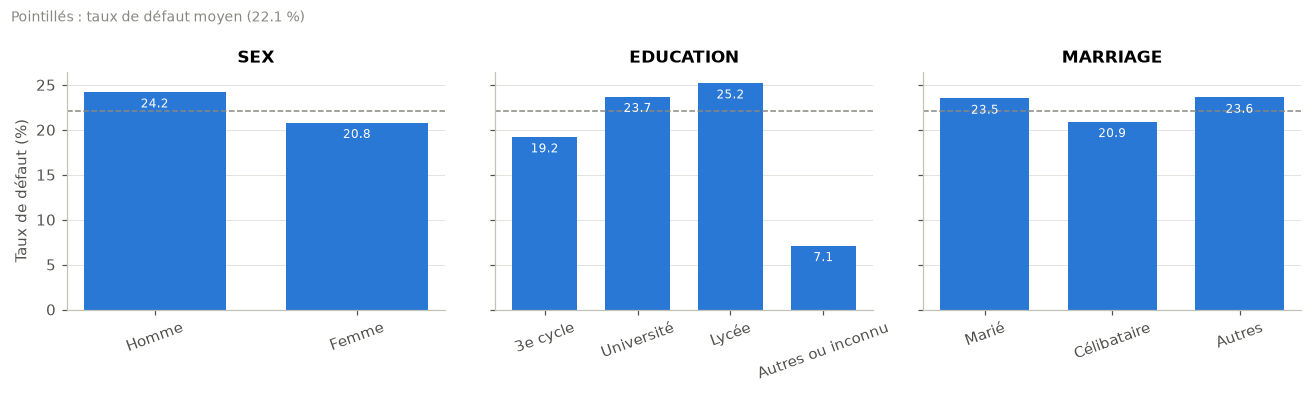

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    barres_taux(ax, positive_rate_by(df, col, TARGET, categorical=True), col)
    ax.tick_params(axis="x", labelrotation=20)
axes[0].set_ylabel("Taux de défaut (%)")
note_moyenne(fig)
fig.tight_layout()
plt.show()

- **SEX :** 24,2 % de défaut chez les hommes contre 20,8 % chez les femmes.
- **EDUCATION :** le risque augmente quand le niveau d'études baisse (3e cycle 19,2 %, université
  23,7 %, lycée 25,2 %) ; « Autres ou inconnu » est nettement plus bas (7,1 %).
- **MARRIAGE :** écart modéré entre marié (23,5 %) et célibataire (20,9 %).

Ces trois variables sont **sensibles** (sexe, situation familiale, niveau d'études) : leur poids dans
les modèles sera mesuré et discuté dans l'analyse d'équité.

### 2.2 Statuts de remboursement : PAY_0 à PAY_6

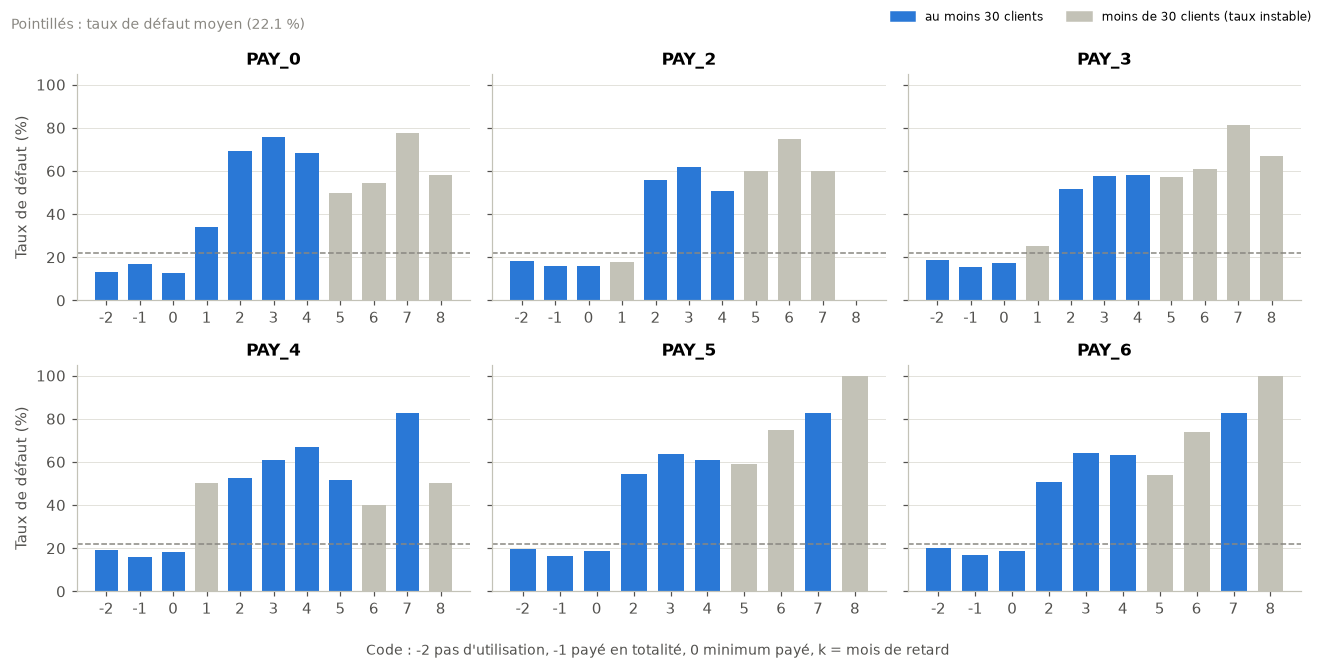

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, col in zip(axes.flat, PAY_STATUS_FEATURES):
    table = positive_rate_by(df, col, TARGET, categorical=False)
    codes = [label.split(" : ")[0] for label in table.index]
    barres_taux(ax, table, col, etiquettes=codes, valeurs=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Taux de défaut (%)")
fig.supxlabel("Code : -2 pas d'utilisation, -1 payé en totalité, 0 minimum payé, k = mois de retard",
              fontsize=9, color="#52514e")
note_moyenne(fig)
fig.legend(handles=[Patch(color=RATE_COLOR, label=f"au moins {PETIT_EFFECTIF} clients"),
                    Patch(color=GRIS, label=f"moins de {PETIT_EFFECTIF} clients (taux instable)")],
           loc="upper right", ncol=2, frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

In [20]:
retards = pd.DataFrame({
    col: df.groupby(df[col] >= 1)[TARGET].mean().mul(100).round(1).rename({False: "sans retard", True: "retard ≥ 1 mois"})
    for col in PAY_STATUS_FEATURES
}).T
retards["clients en retard"] = [(df[col] >= 1).sum() for col in PAY_STATUS_FEATURES]
retards

,sans retard,retard ≥ 1 mois,clients en retard
PAY_0,13.8,50.3,6818
PAY_2,16.3,55.8,4438
PAY_3,17.2,52.3,4213
PAY_4,18.0,53.5,3510
PAY_5,18.4,55.6,2968
PAY_6,18.7,52.3,3079


- Pour chaque mois, le risque est **plat de -2 à 0**, puis **saute** dès qu'il y a du retard : environ
  14 à 19 % sans retard contre 50 à 56 % avec au moins un mois de retard. Relation non linéaire (M05).
- Les barres grises reposent sur moins de 30 clients (par exemple 100 % de défaut pour le code 8 en
  PAY_5 et PAY_6, avec 1 et 2 clients) : leurs hauteurs ne sont pas interprétables.
- L'anomalie de la section 1.4 est visible : le code 1 n'existe presque qu'en septembre (PAY_0).

### 2.3 Plafond de crédit et âge

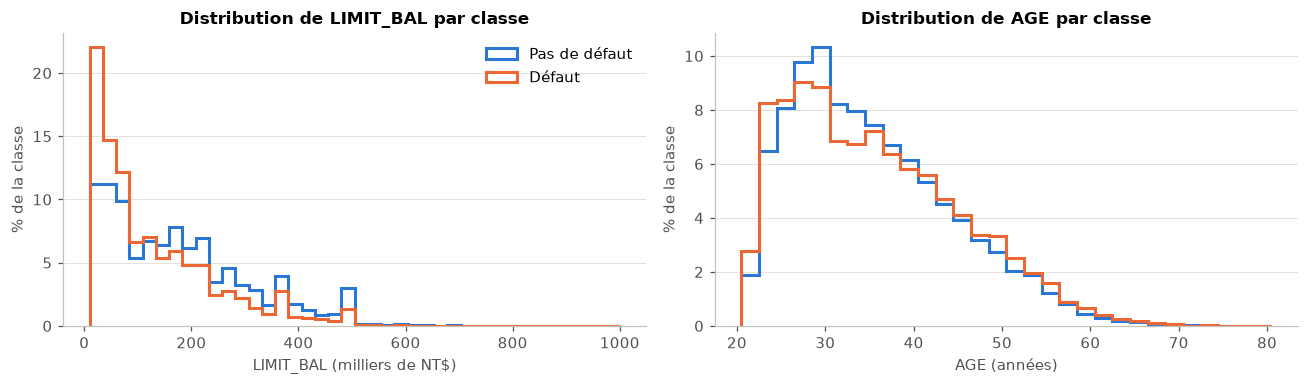

,LIMIT_BAL,AGE
DEFAULT,,
Pas de défaut,150000.0,34.0
Défaut,90000.0,34.0


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
# Âges entiers : tranches de 2 ans exactement, sinon les tranches contiennent tantôt 1, tantôt 2 âges.
for ax, (col, echelle, titre_x, bords) in zip(axes, [
    ("LIMIT_BAL", 1000, "LIMIT_BAL (milliers de NT$)", 40),
    ("AGE", 1, "AGE (années)", np.arange(20.5, 81, 2)),
]):
    valeurs = df[col] / echelle
    bords = np.histogram_bin_edges(valeurs, bins=bords)
    for cls in (0, 1):
        v = valeurs[df[TARGET] == cls]
        # Poids : chaque classe totalise 100 %, pour comparer les formes malgré le déséquilibre.
        ax.hist(v, bins=bords, weights=np.full(len(v), 100 / len(v)), histtype="step",
                linewidth=2, color=CLASS_COLORS[cls], label=NOMS_CLASSES[cls])
    ax.set_title(f"Distribution de {col} par classe")
    ax.set_xlabel(titre_x)
    ax.set_ylabel("% de la classe")
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()
df.groupby(TARGET)[["LIMIT_BAL", "AGE"]].median().rename(index=NOMS_CLASSES)

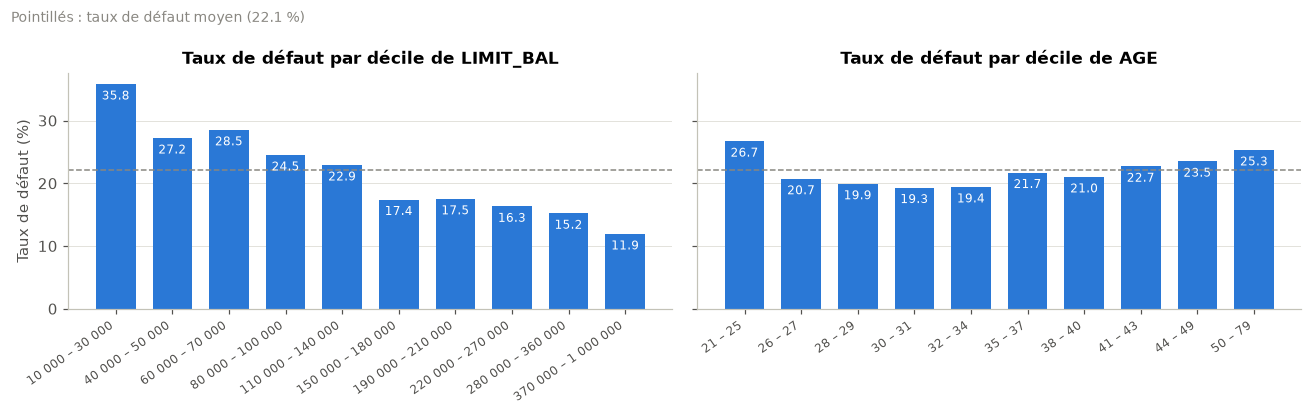

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, ["LIMIT_BAL", "AGE"]):
    table = positive_rate_by(df, col, TARGET, categorical=False, n_bins=10)
    barres_taux(ax, table, f"Taux de défaut par décile de {col}")
    ax.tick_params(axis="x", labelrotation=35, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
axes[0].set_ylabel("Taux de défaut (%)")
note_moyenne(fig)
fig.tight_layout()
plt.show()

- **LIMIT_BAL :** les clients en défaut ont un plafond plus bas (médiane 90 000 contre 150 000) ; le
  taux de défaut baisse régulièrement de 35,8 % (premier décile) à 11,9 % (dernier décile). La banque
  accorde déjà des plafonds plus élevés aux clients qu'elle juge plus sûrs.
- **AGE :** même âge médian dans les deux classes (34 ans), mais une relation **en U** : 26,7 % chez
  les 21-25 ans, environ 19 % vers 30 ans, 25,3 % au-delà de 49 ans. Une corrélation linéaire ne
  verrait presque rien ; les arbres peuvent capter cette forme.

### 2.4 Corrélations entre variables numériques

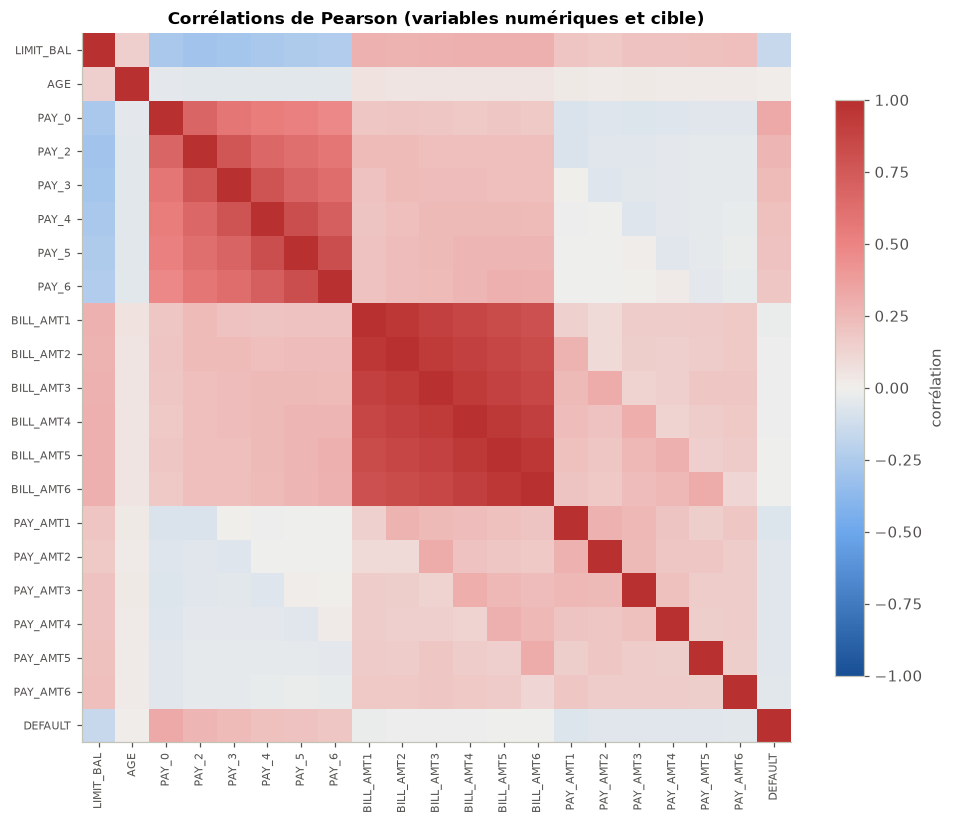

,corrélation avec DEFAULT
PAY_0,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073


In [23]:
numeriques = [c for c in df.columns if c not in CATEGORICAL_FEATURES]
corr = df[numeriques].corr()
palette = LinearSegmentedColormap.from_list("divergente", [(pos, couleur) for pos, couleur in DIVERGING])

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap=palette, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeriques)), numeriques, rotation=90, fontsize=7)
ax.set_yticks(range(len(numeriques)), numeriques, fontsize=7)
ax.grid(False)
ax.set_title("Corrélations de Pearson (variables numériques et cible)")
fig.colorbar(image, ax=ax, shrink=0.8, label="corrélation")
fig.tight_layout()
plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(8).to_frame("corrélation avec DEFAULT")

- **Avec la cible :** PAY_0 est la variable la plus liée au défaut (0,325), puis les autres statuts
  de remboursement (0,26 à 0,19) et le plafond LIMIT_BAL (-0,154). Les montants de factures sont
  presque sans lien linéaire avec le défaut.
- **Entre variables :** les factures des six mois sont très corrélées entre elles (0,80 à 0,95), les
  statuts PAY_* un peu moins (0,47 à 0,82). Cette redondance gêne surtout la lecture des
  **coefficients** de la régression logistique (effets partagés entre variables corrélées) et répartit
  l'importance entre variables voisines dans les explications.
- Les variables catégorielles sont exclues : une corrélation sur des codes sans ordre n'a pas de sens.

### Synthèse de la section 2

| Constat | Conséquence pour la suite |
|---|---|
| Le retard de paiement récent (PAY_0) est le signal le plus fort | Variable attendue en tête des explications |
| Risque plat puis en saut selon PAY_*, en U selon l'âge | Relations non linéaires : avantage probable des arbres (M05) |
| Plafond bas = risque plus élevé | Effet attendu négatif de LIMIT_BAL |
| Factures très corrélées entre mois | Coefficients de la régression logistique à lire avec prudence |
| Écarts selon le sexe, l'éducation, la situation familiale | Analyse d'équité nécessaire |